<a href="https://colab.research.google.com/github/ssinmani/Project_K-Means_ECG/blob/main/K_Means_ECG.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
pip install wfdb

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 2.6 MB/s eta 0:00:00


In [ ]:
import wfdb
import numpy as np
import matplotlib.pyplot as plt

FS = 360                                  # 360 samples per second
RECORDS = ["100", "106", "119", "208"]    # mix of normal + abnormal beats
BEAT_TYPES = ["N", "L", "R", "V", "A"]    # beat symbols we keep

def load_record(rec):
    record = wfdb.rdrecord(rec, pn_dir="mitdb")    # the heart signal
    ann = wfdb.rdann(rec, "atr", pn_dir="mitdb")   # the doctors' notes
    signal = record.p_signal[:, 0]                 # channel 0 = lead MLII
    return signal, np.array(ann.sample), np.array(ann.symbol)

In [ ]:
signal, samples, symbols = load_record("100")
print("Signal length:", len(signal), "samples =", round(len(signal) / FS / 60, 1), "minutes")
print("Number of annotations:", len(samples))

Signal length: 650000 samples = 30.1 minutes
Number of annotations: 2274


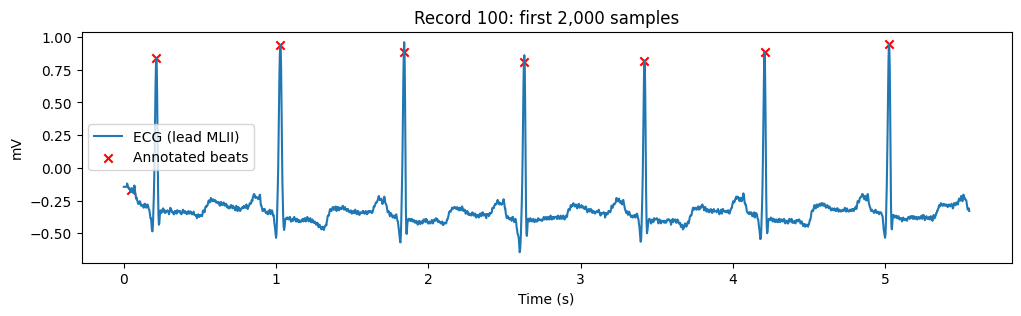

In [ ]:
n = 2000
t = np.arange(n) / FS                     # time in seconds
plt.figure(figsize=(12, 3))
plt.plot(t, signal[:n], label="ECG (lead MLII)")
peaks = samples[samples < n]              # annotations inside the first 2,000 samples
plt.scatter(peaks / FS, signal[peaks], c="r", marker="x", label="Annotated beats")
plt.xlabel("Time (s)")
plt.ylabel("mV")
plt.title("Record 100: first 2,000 samples")
plt.legend()
plt.show()

In [ ]:
print(symbols[:20].tolist())


['+', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'A', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N']


In [ ]:
all_records = {}
for rec in RECORDS:
    all_records[rec] = load_record(rec)
    sym = all_records[rec][2]
    kept = [s for s in sym if s in BEAT_TYPES]
    types, counts = np.unique(kept, return_counts=True)
    print(f"Record {rec}: {dict(zip(types.tolist(), counts.tolist()))}")

In [ ]:
BEFORE = int(0.25 * FS)    # 250 ms before the R peak = 90 samples
AFTER = int(0.40 * FS)     # 400 ms after              = 144 samples

def cut_beats(signal, samples, symbols):
    beats, labels, rr_prev, rr_next = [], [], [], []
    for i in range(1, len(samples) - 1):
        s = samples[i]
        if symbols[i] not in BEAT_TYPES:
            continue                                  # skip notes like '+'
        if s - BEFORE < 0 or s + AFTER > len(signal):
            continue                                  # window falls off the edge
        beats.append(signal[s - BEFORE : s + AFTER])
        labels.append(symbols[i])
        rr_prev.append((s - samples[i - 1]) / FS * 1000)   # ms since previous beat
        rr_next.append((samples[i + 1] - s) / FS * 1000)   # ms until next beat
    return np.array(beats), np.array(labels), np.array(rr_prev), np.array(rr_next)

In [ ]:
b100, l100, _, _ = cut_beats(*all_records["100"])
print("Beats shape:", b100.shape)

In [ ]:
t_beat = (np.arange(BEFORE + AFTER) - BEFORE) / FS * 1000    # ms, 0 = R peak
for i in range(5):
    plt.plot(t_beat, b100[i])
plt.axvline(0, c="k", ls="--", lw=0.8)
plt.xlabel("Time from R peak (ms)")
plt.ylabel("mV")
plt.title("5 beats from record 100")
plt.show()

In [ ]:
b119, l119, _, _ = cut_beats(*all_records["119"])
plt.plot(t_beat, b119[np.where(l119 == "N")[0][0]], label="N (normal)")
plt.plot(t_beat, b119[np.where(l119 == "V")[0][0]], label="V (PVC)")
plt.xlabel("Time from R peak (ms)")
plt.ylabel("mV")
plt.title("Normal vs. PVC beat")
plt.legend()
plt.show()

In [ ]:
def beat_width_ms(beat):
    centre = beat - np.median(beat)          # remove the baseline
    size = np.abs(centre)                    # works for up AND down spikes
    p = BEFORE                               # R peak position
    half = size[p] / 2
    left, right = p, p
    while left > 0 and size[left] >= half:
        left -= 1
    while right < len(beat) - 1 and size[right] >= half:
        right += 1
    return (right - left) / FS * 1000

beats_list, labels_list, feats_list = [], [], []
for rec in RECORDS:
    beats, labels, rr_prev, rr_next = cut_beats(*all_records[rec])
    height = beats.max(axis=1) - beats.min(axis=1)                 # mV
    width = np.array([beat_width_ms(bt) for bt in beats])          # ms
    feats_list.append(np.column_stack([height, width, rr_prev, rr_next]))
    beats_list.append(beats)
    labels_list.append(labels)

beats_all = np.vstack(beats_list)
labels_all = np.concatenate(labels_list)
X_raw = np.vstack(feats_list)
FEATURES = ["height (mV)", "width (ms)", "time since previous beat (ms)", "time to next beat (ms)"]
print("Feature table:", X_raw.shape)
for name, col in zip(FEATURES, X_raw.T):
    print(f"  {name:32s} mean {col.mean():8.2f}   std {col.std():7.2f}")

In [ ]:
mean = X_raw.mean(axis=0)
std = X_raw.std(axis=0)
X = (X_raw - mean) / std
print("Means:", X.mean(axis=0).round(2), " Stds:", X.std(axis=0).round(2))

In [ ]:
def kmeans(X, k, max_iters=100, seed=0):
    rng = np.random.default_rng(seed)

    # 1. INITIALIZE: pick k random rows as starting centres
    centroids = X[rng.choice(len(X), size=k, replace=False)]
    assignments = np.full(len(X), -1)

    for it in range(max_iters):
        # 2. ASSIGN: distance from every point to every centre
        dists = ((X[:, None, :] - centroids[None, :, :]) ** 2).sum(axis=2)
        new_assignments = dists.argmin(axis=1)

        # 4. STOP: if nobody changed group, we're done
        if np.array_equal(new_assignments, assignments):
            break
        assignments = new_assignments

        # 3. UPDATE: move each centre to the mean of its points
        for j in range(k):
            members = X[assignments == j]
            if len(members) > 0:
                centroids[j] = members.mean(axis=0)

    inertia = ((X - centroids[assignments]) ** 2).sum()
    return centroids, assignments, inertia

def kmeans_best_of(X, k, n_init=5):
    runs = [kmeans(X, k, seed=s) for s in range(n_init)]
    return min(runs, key=lambda r: r[2])

In [ ]:
rng = np.random.default_rng(1)
centres_2d = np.array([[0, 0], [6, 6], [0, 7]])
X2 = np.vstack([c + rng.normal(size=(50, 2)) for c in centres_2d])

c2, a2, in2 = kmeans_best_of(X2, 3)
plt.scatter(X2[:, 0], X2[:, 1], c=a2, cmap="viridis", s=20)
plt.scatter(c2[:, 0], c2[:, 1], c="r", marker="X", s=200, label="Centres")
plt.title(f"K-means test on 2D blobs (inertia {in2:.1f})")
plt.legend()
plt.show()

In [ ]:
ks = range(1, 11)
inertias = [kmeans_best_of(X, k)[2] for k in ks]
plt.plot(list(ks), inertias, "o-")
plt.xlabel("K (number of clusters)")
plt.ylabel("Inertia (total squared distance)")
plt.title("Elbow plot")
plt.xticks(list(ks))
plt.savefig("elbow.png", dpi=150)      # saved for the README
plt.show()

In [ ]:
K = 4                                   # <- change to the bend in YOUR elbow plot
centroids, clusters, inertia = kmeans_best_of(X, K)
print("Beats per cluster:", np.bincount(clusters).tolist())

In [ ]:
types_present = [t for t in BEAT_TYPES if t in labels_all]
print("Cluster  " + "".join(f"{t:>7s}" for t in types_present) + "   total")
for j in range(K):
    in_j = labels_all[clusters == j]
    counts = [np.sum(in_j == t) for t in types_present]
    print(f"   {j}     " + "".join(f"{c:7d}" for c in counts) + f"   {len(in_j):5d}")

In [ ]:
fig, axes = plt.subplots(1, K, figsize=(4 * K, 3), sharey=True)
for j in range(K):
    idx = np.where(clusters == j)[0]
    pick = np.random.default_rng(0).choice(idx, size=min(20, len(idx)), replace=False)
    for i in pick:
        axes[j].plot(t_beat, beats_all[i], lw=0.7, alpha=0.6)
    names, counts = np.unique(labels_all[idx], return_counts=True)
    axes[j].set_title(f"Cluster {j}: {len(idx)} beats, mostly '{names[counts.argmax()]}'")
    axes[j].set_xlabel("ms from R peak")
axes[0].set_ylabel("mV")
plt.tight_layout()
plt.savefig("clusters.png", dpi=150)
plt.show()

In [ ]:
for s in range(5):
    _, a_s, in_s = kmeans(X, K, seed=s)
    print(f"seed {s}: inertia {in_s:9.1f}   cluster sizes {sorted(np.bincount(a_s, minlength=K).tolist())}")